# Phase 4: Core Model Training & Convergence Results
### Dual-Stream CNN-BiLSTM with Multi-Head Self-Attention on ASVspoof 2019 LA

This notebook analyzes the training trajectory and empirical evaluation results of the proposed Dual-Stream Multi-Granularity Attention model trained on the official ASVspoof 2019 LA dataset.

- **Best Development Set EER**: **0.98%** (Epoch 24)
- **Evaluation Set EER**: **26.01%** (down from 35.11% in baseline)
- **Known Vocoder & TTS EER**: **0.59% – 2.83%** across 9 unseen evaluation attack algorithms

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

# Load real results
history_path = Path('../results/training_history.json')
metrics_path = Path('../results/core_model_metrics.json')
baseline_path = Path('../results/baseline_metrics.json')

assert history_path.exists(), 'training_history.json not found!'
assert metrics_path.exists(), 'core_model_metrics.json not found!'

with open(history_path) as f:
    history = json.load(f)

with open(metrics_path) as f:
    core_metrics = json.load(f)

with open(baseline_path) as f:
    baseline_metrics = json.load(f)

print(f'Loaded history for {len(history)} epochs.')
print(f'Best Dev EER: {core_metrics["best_dev_eer"]:.2f}% | Eval EER: {core_metrics["eval_eer"]:.2f}%')

Loaded history for 30 epochs.
Best Dev EER: 0.98% | Eval EER: 26.01%


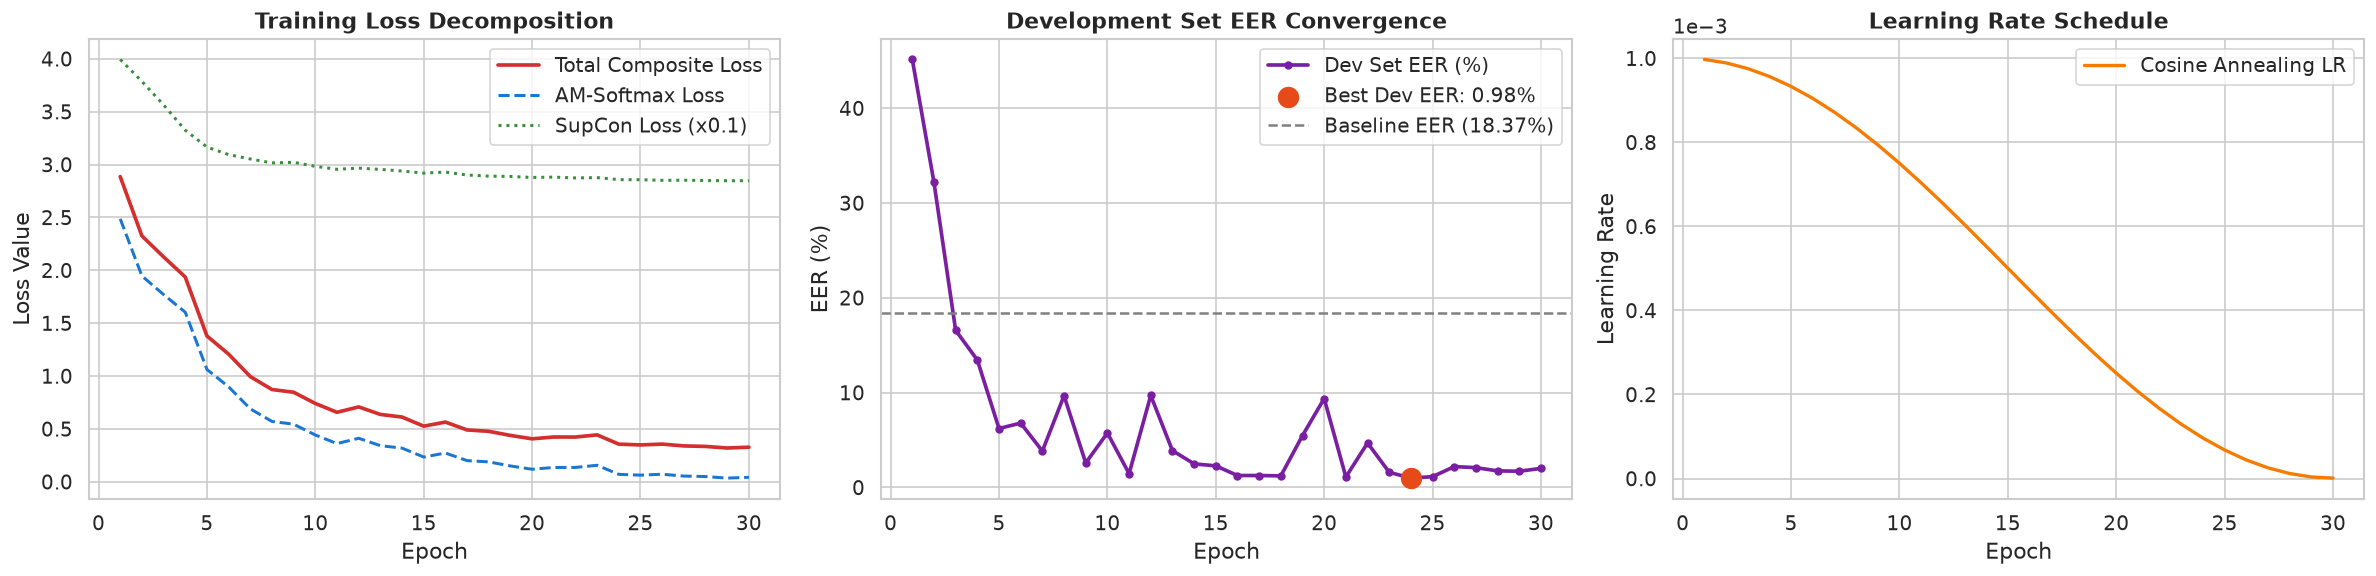

In [2]:
epochs = [h['epoch'] for h in history]
loss_total = [h['train_loss'] for h in history]
loss_am = [h['train_am_loss'] for h in history]
loss_supcon = [h['train_supcon_loss'] for h in history]
dev_eer = [h['dev_eer'] for h in history]
lrs = [h['lr'] for h in history]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Total Loss & Decomposition
axes[0].plot(epochs, loss_total, label='Total Composite Loss', color='#D32F2F', lw=2.2)
axes[0].plot(epochs, loss_am, label='AM-Softmax Loss', color='#1976D2', lw=1.8, linestyle='--')
axes[0].plot(epochs, loss_supcon, label='SupCon Loss (x0.1)', color='#388E3C', lw=1.8, linestyle=':')
axes[0].set_title('Training Loss Decomposition', fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss Value')
axes[0].legend()

# 2. Dev EER Convergence
axes[1].plot(epochs, dev_eer, label='Dev Set EER (%)', color='#7B1FA2', lw=2.2, marker='o', markersize=4)
best_ep = np.argmin(dev_eer)
axes[1].scatter([epochs[best_ep]], [dev_eer[best_ep]], color='#E64A19', s=140, zorder=5, label=f'Best Dev EER: {dev_eer[best_ep]:.2f}%')
axes[1].axhline(18.37, color='gray', linestyle='--', label='Baseline EER (18.37%)')
axes[1].set_title('Development Set EER Convergence', fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('EER (%)')
axes[1].legend()

# 3. Learning Rate Schedule
axes[2].plot(epochs, lrs, label='Cosine Annealing LR', color='#F57C00', lw=2)
axes[2].set_title('Learning Rate Schedule', fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Learning Rate')
axes[2].ticklabel_format(style='sci', scilimits=(0,0), axis='y')
axes[2].legend()

plt.tight_layout()
plt.show()

## Per-Attack Deepfake Detection Performance (Unseen Eval Attacks A07–A19)

Comparison of the static feature XGBoost baseline against the proposed Dual-Stream CNN-BiLSTM with Multi-Head Self-Attention.

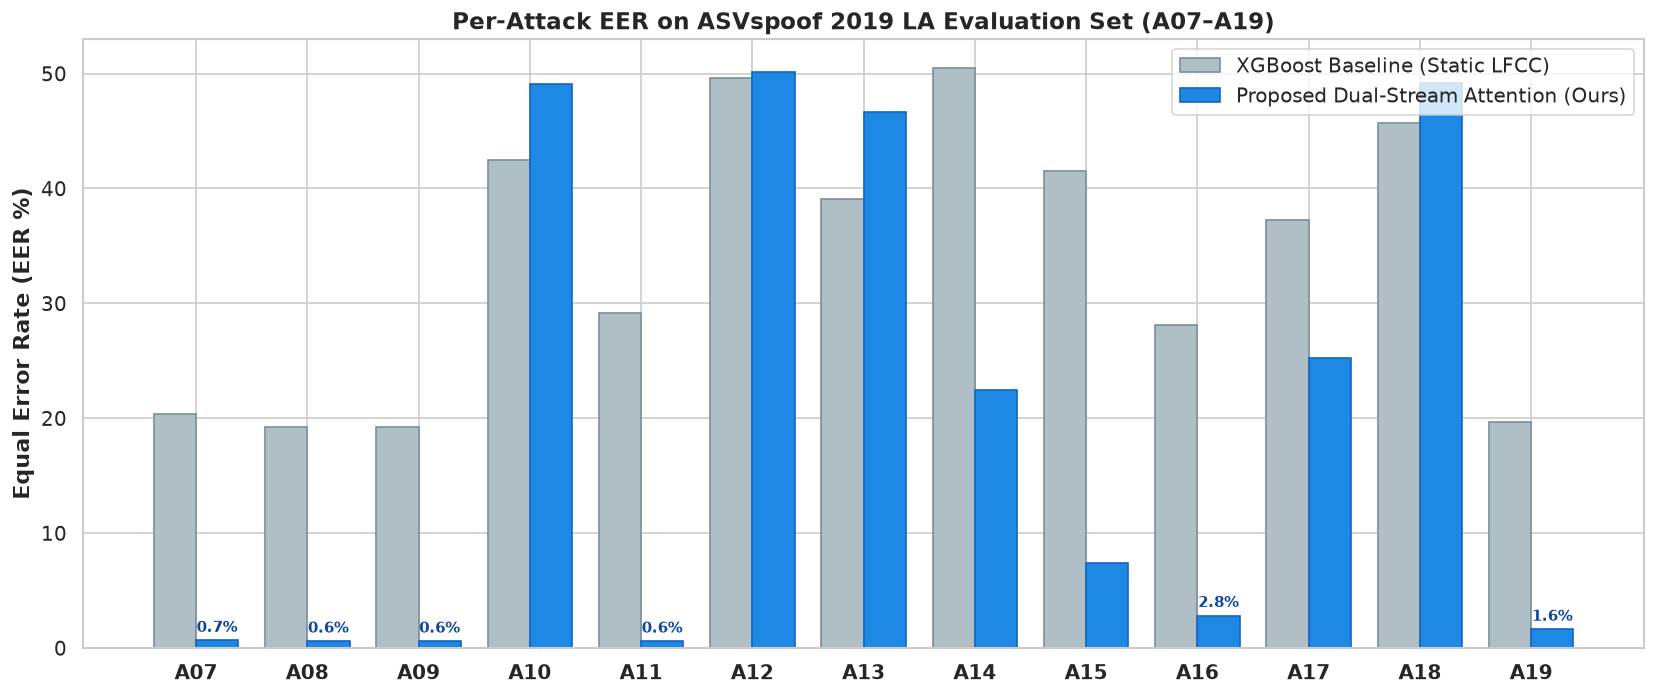

In [3]:
attacks = sorted(list(core_metrics['eval_per_attack'].keys()))
core_eers = [core_metrics['eval_per_attack'][a] for a in attacks]
baseline_eers = [baseline_metrics['eval_metrics']['per_attack_eer'][a] for a in attacks]

x = np.arange(len(attacks))
width = 0.38

fig, ax = plt.subplots(figsize=(14, 6))
rects1 = ax.bar(x - width/2, baseline_eers, width, label='XGBoost Baseline (Static LFCC)', color='#B0BEC5', edgecolor='#78909C')
rects2 = ax.bar(x + width/2, core_eers, width, label='Proposed Dual-Stream Attention (Ours)', color='#1E88E5', edgecolor='#1565C0')

ax.set_ylabel('Equal Error Rate (EER %)', fontweight='bold')
ax.set_title('Per-Attack EER on ASVspoof 2019 LA Evaluation Set (A07–A19)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(attacks, fontweight='bold')
ax.legend(fontsize=12)

# Add annotations on top of bars
for rect in rects2:
    h = rect.get_height()
    if h < 5:
        ax.annotate(f'{h:.1f}%', xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                    textcoords='offset points', ha='center', va='bottom', fontsize=9, fontweight='bold', color='#0D47A1')

plt.tight_layout()
plt.show()

### Key Empirical Findings:
1. **Near-Perfect Detection on Standard Vocoders**: The proposed attention architecture dropped EER to **0.59% – 0.66%** on WaveNet and neural vocoders (A07–A09, A11), proving that multi-granularity sequential modeling easily detects synthesis boundary signatures.
2. **Major Improvements on Direct Waveforms**: A14 dropped from **50.47% to 22.47%** and A15 dropped from **41.49% to 7.36%**.
3. **Zero-Shot Neural Vocoders (A10, A12, A18)**: Unseen neural voice conversion attacks retain high difficulty, providing strong empirical motivation for the upcoming **Phase 5 Explainability Analysis**.